In [1]:
# 1. Import Library

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
#2 Load the iris dataset

iris = load_iris()

X = iris.data # Features
y = iris.target #target

print("Feature names:" , iris.feature_names)
print("Target names:" , iris.target_names)

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']


In [3]:
#3 Feature Scaling

scaler =  StandardScaler()
X_scaled = scaler.fit_transform(X)

In [4]:
#4 Apply K-Means Clustering

kmeans =  KMeans(n_clusters = 3, random_state=42, n_init = 10)
clusters  = kmeans.fit_predict(X_scaled)

centroids= kmeans.cluster_centers_

In [5]:
#5 Reduce Dimensions for Visualization (PCA)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(centroids)

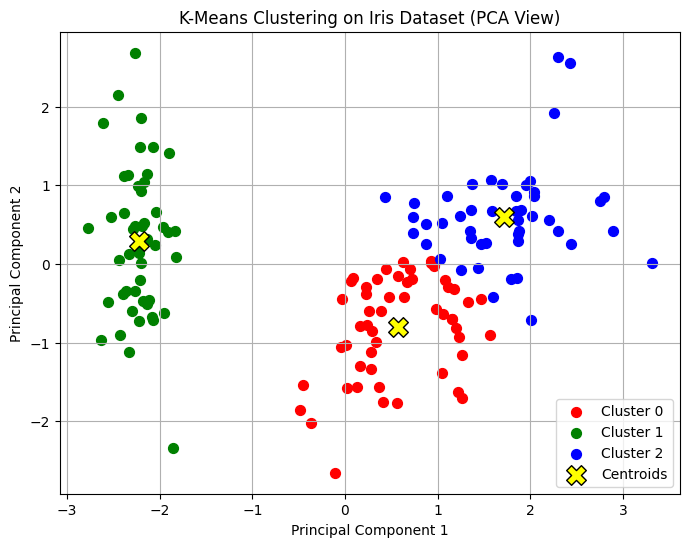

In [6]:
#6

plt.figure(figsize=(8, 6))

colors = ['red', 'green', 'blue']

for i in range(3):
    plt.scatter(
        X_pca[clusters == i,0],
        X_pca[clusters == i,1], 
        s=50,
        color = colors[i],
        label = f"Cluster {i}"
    )

# Plot Centroid
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1], 
    s=200,
    c='yellow',
    marker= 'X',
    edgecolor='black',
    label='Centroids'
)

plt.title("K-Means Clustering on Iris Dataset (PCA View)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid()
plt.show()